# SMS Spam Detection with TF-IDF: a simple filter, tested properly

**The question:** text messages are short, and spam is a small share of them. A bag-of-words model can sort them with about 98% accuracy, so the headline number is not the interesting part. *What does spam actually look like, did the legacy shortcuts (fitting the vocabulary on all the data, ignoring duplicate messages) inflate the score, which text features really help, and what happens when spammers disguise their words?*

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Audit the data
4. Hypotheses and why we chose each test
5. H1: what does spam look like?
6. The models
7. H2: does fitting the vocabulary on all the data flatter the score?
8. H3: do duplicate messages flatter the score?
9. H4: which model is best?
10. H5: what if spammers disguise their words?
11. Where the best model goes wrong
12. Takeaways
13. Limitations

**Run it:** `uv run jupyter lab NLP/spam-detection-tfidf/spam_detection_tfidf.ipynb`, or *Run All* in any Jupyter. The data (about 200 KB, from the UCI repository) downloads itself on the first run, and it takes about 5 minutes on a CPU.

## 1. 💡 The simple analogy

Imagine a **mail clerk sorting letters** into "real" and "junk" by looking at the words.

- A **bag of words** clerk just counts which words appear and in what numbers, without caring about order. "FREE prize, call now" has a very junk-like word count.
- **TF-IDF** makes the clerk smarter: a word that appears in every letter ("the", "I") tells her nothing, so it counts for little; a rare word that shows up mostly in junk ("txt", "claim") counts for a lot.
- **Character n-grams** make her read the *shapes* of words: she sees "fr33" and "free" share the letters "fr", so a disguised word still looks familiar.
- **Naive Bayes** and **logistic regression** are two ways to turn those word weights into a verdict.
- A **leaky test** is a clerk who is given the *exam letters* to study from before the exam: they might only have memorised them. We check whether that happened.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the seed and the number of cross-validation repeats keeps the notebook reproducible and avoids "magic numbers".

In [1]:
import csv
import re
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from nltk.stem.porter import PorterStemmer
from scipy import stats
from sklearn.base import clone
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import FeatureUnion, Pipeline
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
DATA_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
SEED = 365
N_REPEATS = 5  # repeats of 5-fold cross-validation
N_BOOTSTRAP = 2_000
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if p < 1e-300 else f"{p:.1e}"

## 3. Audit the data first

*What:* download the UCI SMS Spam Collection (5,574 text messages, labelled "ham" for a normal message or "spam"), and look at the class balance, the length of messages and, importantly, **duplicates**: the same text appearing many times. *Why:* spam is often sent in bulk, so the same message can appear several times, and duplicates can leak between training and test data.

> **Problems in the legacy script this replaces:** it fitted the **vocabulary on all the messages before splitting** into train and test; it used one random split and reported **accuracy** (98.8%) when 87% of messages are ham, so "always say ham" would already score 87%; it never looked at duplicates; it was named "TF-IDF" and described as a "fake news" classifier but used a plain **count** vectoriser and SMS data; it re-built the English stop-word list for every word of every message; and its `pandas` read silently **dropped 2 messages** (the file contains quote characters).

In [2]:
def load_sms() -> pd.DataFrame:
    """Downloads the UCI SMS Spam Collection (once, into ``data/``) and loads it.

    Returns:
        One row per message with columns ``label`` ("ham" or "spam") and ``message``.

    Raises:
        ValueError: If the file does not have the expected number of messages.
    """
    path = DATA_DIR / "SMSSpamCollection"
    if not path.exists():
        archive = DATA_DIR / "sms_spam_collection.zip"
        urllib.request.urlretrieve(DATA_URL, archive)
        with zipfile.ZipFile(archive) as zf:
            zf.extract("SMSSpamCollection", DATA_DIR)
    table = pd.read_csv(
        path, sep="\t", names=["label", "message"], encoding="utf-8", quoting=csv.QUOTE_NONE
    )  # default quoting silently drops 2 messages
    if len(table) != 5_574 or set(table["label"]) != {"ham", "spam"}:
        raise ValueError("Unexpected SMS Spam Collection file")
    return table


sms = load_sms()
sms["spam"] = (sms["label"] == "spam").astype(int)
sms["group"] = sms["message"].str.lower().str.strip()  # identical texts form one group
y = sms["spam"].to_numpy()
groups = pd.factorize(sms["group"])[0]
dupes = sms["group"].duplicated(keep=False)
conflict = sms.groupby("group")["label"].nunique().gt(1).sum()
print(f"{len(sms):,} messages: {y.sum():,} spam ({y.mean():.1%}) and {(1 - y).sum():,.0f} ham")
print(f"Always guessing 'ham' scores {1 - y.mean():.1%} accuracy")
print(
    f"Messages whose exact text appears more than once: {dupes.sum():,} "
    f"({dupes.mean():.1%}); distinct texts: {sms['group'].nunique():,}"
)
spam_dupe_share = sms[sms["spam"] == 1]["group"].duplicated(keep=False).mean()
ham_dupe_share = sms[sms["spam"] == 0]["group"].duplicated(keep=False).mean()
print(
    f"Share of spam messages that have an exact copy: {spam_dupe_share:.1%}; "
    f"of ham: {ham_dupe_share:.1%}"
)
print(f"Texts that appear with both labels: {conflict}")
print(
    f"Characters per message: ham median {sms[sms['spam'] == 0]['message'].str.len().median():.0f}"
    f", spam median {sms[sms['spam'] == 1]['message'].str.len().median():.0f}"
)

5,574 messages: 747 spam (13.4%) and 4,827 ham
Always guessing 'ham' scores 86.6% accuracy
Messages whose exact text appears more than once: 705 (12.6%); distinct texts: 5,159
Share of spam messages that have an exact copy: 26.8%; of ham: 10.5%
Texts that appear with both labels: 0
Characters per message: ham median 52, spam median 149


**How to read this:**

- **5,574 messages:** **747 spam (13.4%)** and **4,827 ham**. Always guessing "ham" scores **86.6%** accuracy, so accuracy alone says little.
- **Duplicates are common:** **705 messages (12.6%)** share their exact text with another message, leaving **5,159 distinct texts**. Spam is copied far more: **26.8%** of spam messages have an exact copy, against **10.5%** of ham. No text appears with both labels, so the labels are consistent.
- **Spam is longer:** the median spam is **149 characters**, the median ham **52**.
- The default `pandas` reader returns only 5,572 messages from this file (quote characters break two lines); we read it with quoting turned off to get all 5,574.

## 4. Hypotheses and why we chose each test

| # | Question | H₀ (nothing interesting) | Hₐ | Test |
|---|---|---|---|---|
| H1 | Does spam differ from ham in simple surface features? | Same distribution | Differs | Mann-Whitney U per feature, Holm correction, Cliff's δ and AUC |
| H2 | Does fitting the vocabulary on all messages (legacy) inflate accuracy? | Same accuracy | Legacy is higher | 25 paired folds, Wilcoxon |
| H3 | Do duplicate messages straddling train and test inflate accuracy? | Same accuracy | Random folds are higher | 25 paired folds (random vs grouped by exact text), Wilcoxon |
| H4 | Do richer text features beat the legacy model? | Same average precision | Differs | 25 grouped folds, Nadeau-Bengio corrected paired t-test, Holm |
| H5 | Does disguising words hurt word-based filters more than character-based ones? | Same recall at every disguise level | Differs | Recall with Wilson CIs; exact McNemar on the same messages |

*Why these tests?* Message features are skewed, so rank-based tests (Mann-Whitney, Wilcoxon) are safer than t-tests. With 5,574 messages almost any difference is "significant", so we report **Cliff's δ** (+1 means spam is always higher). Cross-validation folds share training data, so their scores are not independent: the **Nadeau-Bengio correction** widens the standard error to allow for that. **Average precision** (the area under the precision-recall curve) judges a model's *ranking* of messages without choosing a threshold, and works for an unbalanced problem.

## 5. H1: what does spam look like?

*What:* before any model, six simple facts about each message: number of characters, digits, share of capital letters, whether it contains a run of 5 or more digits (phone numbers, prize codes), whether it contains a web link, and how many exclamation marks. We compare spam with ham using Mann-Whitney U tests with Holm's correction for six tests, and report **Cliff's δ** and the **AUC** of each feature used alone. *Why:* it shows what a very simple filter could use, and gives a yardstick for the models later.

In [3]:
text = sms["message"]
surface = pd.DataFrame(
    {
        "characters": text.str.len(),
        "digits": text.str.count(r"\d"),
        "share of capital letters": text.apply(
            lambda s: sum(c.isupper() for c in s) / max(sum(c.isalpha() for c in s), 1)
        ),
        "has a run of 5+ digits": text.str.contains(r"\d{5,}").astype(int),
        "has a web link": text.str.contains(r"(?i)www\.|http|\.com|\.co\.uk").astype(int),
        "exclamation marks": text.str.count("!"),
    }
)
rows = []
for name in surface:
    a, b = surface.loc[y == 1, name], surface.loc[y == 0, name]
    test = stats.mannwhitneyu(a, b)
    rows.append(
        {
            "feature": name,
            "spam median": a.median(),
            "ham median": b.median(),
            "AUC": test.statistic / (len(a) * len(b)),
            "cliffs_delta": 2 * test.statistic / (len(a) * len(b)) - 1,
            "p": test.pvalue,
        }
    )
h1 = pd.DataFrame(rows).set_index("feature")
h1["p_holm"] = multipletests(h1["p"], method="holm")[1]
pd.options.display.float_format = "{:,.3g}".format
print(h1.to_string())
pd.reset_option("display.float_format")

                          spam median  ham median   AUC  cliffs_delta         p    p_holm
feature                                                                                  
characters                        149          52 0.872         0.745 5.97e-236 2.39e-235
digits                             16           0 0.965         0.931         0         0
share of capital letters        0.148      0.0455 0.824         0.648 3.89e-179 1.17e-178
has a run of 5+ digits              1           0 0.891         0.783         0         0
has a web link                      0           0 0.589         0.179 1.95e-171 3.89e-171
exclamation marks                   0           0 0.687         0.374 1.06e-142 1.06e-142


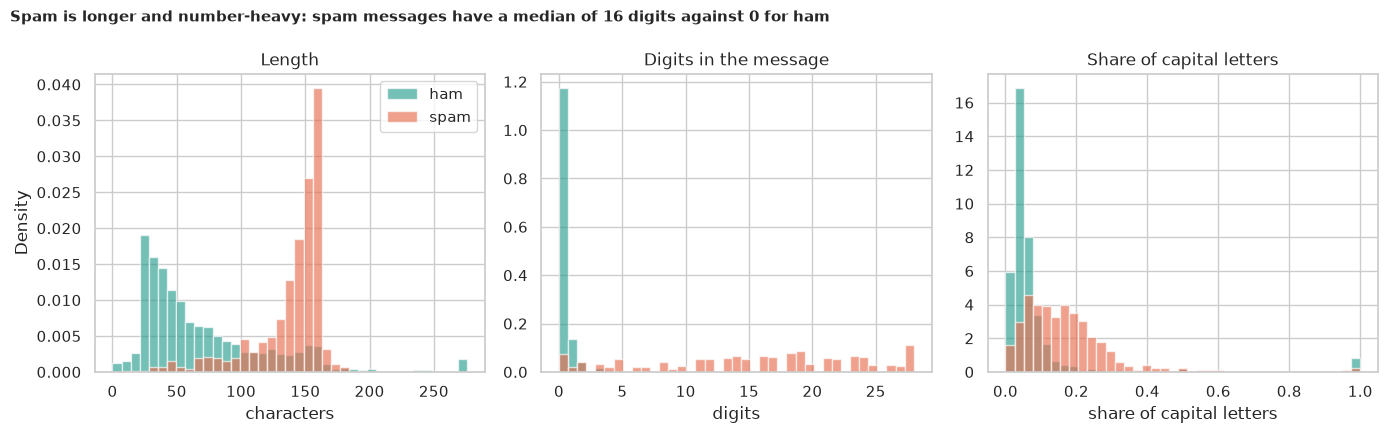

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, column, title in [
    (axes[0], "characters", "Length"),
    (axes[1], "digits", "Digits in the message"),
    (axes[2], "share of capital letters", "Share of capital letters"),
]:
    upper = surface[column].quantile(0.99)
    bins = np.linspace(0, upper, 40)
    ax.hist(
        surface.loc[y == 0, column].clip(upper=upper),
        bins=bins,
        alpha=0.65,
        color=TEAL,
        density=True,
        label="ham",
    )
    ax.hist(
        surface.loc[y == 1, column].clip(upper=upper),
        bins=bins,
        alpha=0.65,
        color=ORANGE,
        density=True,
        label="spam",
    )
    ax.set_title(title)
    ax.set_xlabel(column)
axes[0].set_ylabel("Density")
axes[0].legend()
fig.suptitle(
    f"Spam is longer and number-heavy: spam messages have a median of "
    f"{h1.loc['digits', 'spam median']:.0f} digits against "
    f"{h1.loc['digits', 'ham median']:.0f} for ham",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_surface_features.png", dpi=150)
plt.show()

**How to read this:**

- **The number of digits is the strongest single clue:** a median of **16** digits in spam against **0** in ham, Cliff's δ = **0.931** and an AUC of **0.965** for that one number. A run of five or more digits (a phone number or a prize code) has δ = **0.783** (AUC 0.891).
- **Spam is longer and shoutier:** characters δ = **0.745** (median 149 against 52), share of capital letters δ = **0.648** (median 14.8% against 4.6%). Exclamation marks are weaker (δ = **0.374**) and a web link is the weakest (δ = **0.179**, AUC 0.589).
- All six differences are significant (Holm-adjusted p below 1e-140); **we reject H₀** for each. A one-line rule "more than a few digits" already ranks messages well, which sets the bar the models have to clear.

## 6. The models

*What:* four text classifiers, each built as a scikit-learn **pipeline** so that the vocabulary is learned from the **training messages only**:

1. **Legacy:** letters only, lower case, stop words removed, Porter stemming, a word-count table with at most 2,500 words, **Multinomial Naive Bayes**.
2. **Raw words + Naive Bayes:** no stemming and no stop-word removal, all words that occur at least twice.
3. **TF-IDF words + logistic regression:** single words and pairs, with TF-IDF weighting.
4. **TF-IDF words + characters + logistic regression:** the same, plus character n-grams (2 to 5 letters inside each word).

We judge them mainly by **average precision** (how well spam is ranked above ham), and also by accuracy, spam recall and the false-alarm rate at the usual 0.5 threshold.

In [5]:
stemmer = PorterStemmer()
stop = set(ENGLISH_STOP_WORDS)
_stem_cache: dict[str, str] = {}


def legacy_clean(message: str) -> str:
    """The legacy preprocessing: letters only, lower case, no stop words, Porter-stemmed.

    Args:
        message: A raw text message.

    Returns:
        The cleaned message as a space-separated string.
    """
    words = re.sub("[^a-zA-Z]", " ", message).lower().split()
    out = []
    for word in words:
        if word in stop:
            continue
        if word not in _stem_cache:
            _stem_cache[word] = stemmer.stem(word)
        out.append(_stem_cache[word])
    return " ".join(out)


sms["legacy"] = sms["message"].map(legacy_clean)


def make_models() -> dict[str, Pipeline]:
    """The four text classifiers compared in this notebook (all start from raw text columns).

    Returns:
        A dict from model name to an unfitted scikit-learn pipeline. The vectoriser is part of
        each pipeline, so it is fitted on training messages only.
    """
    word_tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    char_tfidf = TfidfVectorizer(
        analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True
    )
    return {
        "legacy: stemmed counts + Naive Bayes": Pipeline(
            [("vec", CountVectorizer(max_features=2500)), ("clf", MultinomialNB())]
        ),
        "raw words + Naive Bayes": Pipeline(
            [("vec", CountVectorizer(lowercase=True, min_df=2)), ("clf", MultinomialNB())]
        ),
        "TF-IDF words + logistic regression": Pipeline(
            [("vec", word_tfidf), ("clf", LogisticRegression(C=10, max_iter=2000))]
        ),
        "TF-IDF words + characters + logistic regression": Pipeline(
            [
                ("vec", FeatureUnion([("word", clone(word_tfidf)), ("char", char_tfidf)])),
                ("clf", LogisticRegression(C=10, max_iter=2000)),
            ]
        ),
    }


def model_input(name: str) -> pd.Series:
    """Which text column a model reads: the legacy model reads the pre-cleaned text."""
    return sms["legacy"] if name.startswith("legacy") else sms["message"]


def spam_score(model: Pipeline, texts: pd.Series) -> np.ndarray:
    """Probability of spam for each message.

    Args:
        model: A fitted pipeline.
        texts: The messages to score.

    Returns:
        Spam probabilities.
    """
    return model.predict_proba(texts)[:, 1]

**How to read this:** these cells only define the models and helpers, so there is nothing to interpret yet. The results start in the next sections.

## 7. H2: does fitting the vocabulary on all the data flatter the score?

*What:* the legacy script built its word table (the 2,500 most common words) from **all** messages and only then split them into train and test, so the test messages helped choose the vocabulary. We compare it, fold by fold, with building the vocabulary from the training messages only, for the same legacy model, over 5 repeats of 5-fold cross-validation (25 folds). *Why it might matter:* the test messages are not supposed to influence anything the model sees.

In [6]:
legacy_texts = sms["legacy"]
leak_rows = []
for repeat in range(N_REPEATS):
    splitter = StratifiedKFold(5, shuffle=True, random_state=SEED + repeat)
    for fold, (tr, te) in enumerate(splitter.split(legacy_texts, y)):
        clean_vec = CountVectorizer(max_features=2500).fit(legacy_texts.iloc[tr])
        leaky_vec = CountVectorizer(max_features=2500).fit(legacy_texts)  # the legacy mistake
        scores = {}
        for name, vec in [
            ("fitted on training messages only", clean_vec),
            ("fitted on all messages (legacy)", leaky_vec),
        ]:
            clf = MultinomialNB().fit(vec.transform(legacy_texts.iloc[tr]), y[tr])
            pred = clf.predict(vec.transform(legacy_texts.iloc[te]))
            scores[name] = (pred == y[te]).mean()
        leak_rows.append({"repeat": repeat, "fold": fold, **scores})
leak = pd.DataFrame(leak_rows)
diff = (
    leak["fitted on all messages (legacy)"] - leak["fitted on training messages only"]
).to_numpy()
wil = stats.wilcoxon(diff) if np.any(diff != 0) else None
print(f"Accuracy over {len(leak)} folds (5 folds x {N_REPEATS} repeats):")
print(
    f"  vectoriser fitted on training messages only: "
    f"{leak['fitted on training messages only'].mean():.4f}"
)
print(
    f"  vectoriser fitted on all messages (legacy):  "
    f"{leak['fitted on all messages (legacy)'].mean():.4f}"
)
print(
    f"Difference {diff.mean() * 100:+.3f} points (leaky higher in {(diff > 0).sum()} folds, "
    f"lower in {(diff < 0).sum()}, equal in {(diff == 0).sum()}); "
    f"Wilcoxon p = {fmt_p(wil.pvalue) if wil is not None else 'n/a'}"
)
legacy_tr, legacy_te = train_test_split(np.arange(len(sms)), test_size=0.2, random_state=SEED)
vec = CountVectorizer(max_features=2500).fit(legacy_texts)
single = MultinomialNB().fit(vec.transform(legacy_texts.iloc[legacy_tr]), y[legacy_tr])
single_acc = (single.predict(vec.transform(legacy_texts.iloc[legacy_te])) == y[legacy_te]).mean()
print(f"\nThe legacy recipe on one 80/20 split (seed {SEED}): accuracy {single_acc:.4f}")

Accuracy over 25 folds (5 folds x 5 repeats):
  vectoriser fitted on training messages only: 0.9827
  vectoriser fitted on all messages (legacy):  0.9822
Difference -0.050 points (leaky higher in 5 folds, lower in 12, equal in 8); Wilcoxon p = 2.5e-01

The legacy recipe on one 80/20 split (seed 365): accuracy 0.9821


**How to read this:**

- **It makes no practical difference here:** mean accuracy is **0.9827** with the vocabulary built from training messages only and **0.9822** with the legacy method, a difference of **-0.050 points**. The leaky version was higher in only 5 of 25 folds, lower in 12 and equal in 8 (Wilcoxon p = 0.25). **We fail to reject H₀.**
- A vocabulary of the 2,500 most common words barely changes whether or not rare test words are included, because common words dominate. This leak is a bad habit, not a big problem, on this dataset.
- The legacy recipe on one 80/20 split reaches **0.9821** here (the legacy script reported 98.83% on its own split), which is within the fold-to-fold spread (about ±0.5 points), so one split cannot say more than that.

## 8. H3: do duplicate messages flatter the score?

*What:* 12.6% of the messages have an exact copy elsewhere. In ordinary random cross-validation, a message and its copy can land on opposite sides of the split, so the model is tested on text it has already seen. We compare the legacy model under **random folds** with the same model under **folds grouped by exact text** (copies always stay together), 25 paired folds each. *Why:* a leak like this inflates accuracy in exactly the way people forget to check.

In [7]:
def cv_scores(name: str, splitter_factory, n_repeats: int = N_REPEATS) -> pd.DataFrame:
    """Cross-validated average precision, accuracy, spam recall and ham false-alarm rate.

    Args:
        name: Model name (key of ``make_models``).
        splitter_factory: Callable taking a repeat number and returning a splitter.
        n_repeats: Number of repeats of 5-fold cross-validation.

    Returns:
        One row per fold with the scores.
    """
    texts = model_input(name)
    rows = []
    for repeat in range(n_repeats):
        splitter = splitter_factory(repeat)
        group_arg = groups if isinstance(splitter, StratifiedGroupKFold) else None
        for fold, (tr, te) in enumerate(splitter.split(texts, y, group_arg)):
            model = make_models()[name].fit(texts.iloc[tr], y[tr])
            prob = spam_score(model, texts.iloc[te])
            pred = prob > 0.5
            truth = y[te]
            rows.append(
                {
                    "model": name,
                    "repeat": repeat,
                    "fold": fold,
                    "n_test": len(te),
                    "ap": average_precision_score(truth, prob),
                    "accuracy": (pred == truth).mean(),
                    "recall": pred[truth == 1].mean(),
                    "false_alarm": pred[truth == 0].mean(),
                }
            )
    return pd.DataFrame(rows)


name0 = "legacy: stemmed counts + Naive Bayes"
random_cv = cv_scores(name0, lambda r: StratifiedKFold(5, shuffle=True, random_state=SEED + r))
grouped_cv = cv_scores(
    name0, lambda r: StratifiedGroupKFold(5, shuffle=True, random_state=SEED + r)
)
print(f"Legacy model, {len(random_cv)} folds each:")
for label, frame in [
    ("random folds (duplicates can straddle)", random_cv),
    ("folds grouped by exact text", grouped_cv),
]:
    print(
        f"  {label}: accuracy {frame['accuracy'].mean():.4f}, average precision "
        f"{frame['ap'].mean():.4f}, spam recall {frame['recall'].mean():.4f}, "
        f"ham false-alarm rate {frame['false_alarm'].mean():.4f}"
    )
diff = random_cv["accuracy"].to_numpy() - grouped_cv["accuracy"].to_numpy()
wil = stats.wilcoxon(diff)
print(
    f"Random minus grouped accuracy: {diff.mean() * 100:+.3f} points "
    f"(random higher in {(diff > 0).sum()} of {len(diff)} folds); Wilcoxon p = {fmt_p(wil.pvalue)}"
)
print("Messages in the test fold that have an exact copy in the training fold (random folds):")
copy_share = []
for tr, te in StratifiedKFold(5, shuffle=True, random_state=SEED).split(legacy_texts, y):
    copy_share.append(np.isin(groups[te], groups[tr]).mean())
print(f"  {np.mean(copy_share):.1%} on average (grouped folds: 0%)")

Legacy model, 25 folds each:
  random folds (duplicates can straddle): accuracy 0.9827, average precision 0.9707, spam recall 0.9320, ham false-alarm rate 0.0094
  folds grouped by exact text: accuracy 0.9818, average precision 0.9697, spam recall 0.9277, ham false-alarm rate 0.0098
Random minus grouped accuracy: +0.090 points (random higher in 14 of 25 folds); Wilcoxon p = 3.3e-01
Messages in the test fold that have an exact copy in the training fold (random folds):
  11.1% on average (grouped folds: 0%)


**How to read this:**

- **Duplicates do straddle the split:** in random folds **11.1%** of the test messages have an exact copy in the training messages (0% in the grouped folds).
- **But the score barely moves:** accuracy **0.9827** with random folds against **0.9818** with grouped folds, a difference of **+0.090 points** (random higher in 14 of 25 folds, Wilcoxon p = 0.33). Average precision is **0.9707** against **0.9697**, and spam recall **0.9320** against **0.9277**. **We fail to reject H₀.**
- So the duplicates are not what makes the scores high; the task is simply easy. The grouped folds are still the right default (they can only be more honest), and we use them from here on.

## 9. H4: which model is best?

*What:* the four models, each scored on the same **25 grouped folds**. We compare each of the three alternatives with the legacy model on **average precision** using the **Nadeau-Bengio corrected paired t-test** (it allows for the folds sharing training data) with Holm's correction for three comparisons. *Why:* "98% accuracy" cannot tell a good filter from an average one, and the difference between filters lies in the rare errors.

In [8]:
all_cv = pd.concat(
    [
        cv_scores(name, lambda r: StratifiedGroupKFold(5, shuffle=True, random_state=SEED + r))
        if name != name0
        else grouped_cv
        for name in make_models()
    ]
)
summary = all_cv.groupby("model", sort=False)[["ap", "accuracy", "recall", "false_alarm"]].agg(
    ["mean", "std"]
)
print(summary.round(4).to_string())


def corrected_paired_t(a: np.ndarray, b: np.ndarray, test_over_train: float = 0.25) -> tuple:
    """Nadeau-Bengio corrected paired t-test for scores from repeated cross-validation.

    Folds share training data, so their scores are not independent; the correction widens the
    standard error to allow for this.

    Args:
        a: Scores of model A, one per fold.
        b: Scores of model B on the same folds.
        test_over_train: Size of a test fold divided by the size of a training fold.

    Returns:
        The mean difference (A minus B), its corrected standard error and the p-value.
    """
    d = a - b
    n = len(d)
    se = np.sqrt((1 / n + test_over_train) * d.var(ddof=1))
    t = d.mean() / se if se > 0 else 0.0
    return float(d.mean()), float(se), float(2 * stats.t.sf(abs(t), n - 1))


best = "TF-IDF words + characters + logistic regression"
ref = all_cv[all_cv["model"] == name0].sort_values(["repeat", "fold"])["ap"].to_numpy()
cmp_rows = []
for name in list(make_models())[1:]:
    other = all_cv[all_cv["model"] == name].sort_values(["repeat", "fold"])["ap"].to_numpy()
    mean_d, se, p = corrected_paired_t(other, ref)
    cmp_rows.append({"model vs legacy": name, "AP difference": mean_d, "corrected SE": se, "p": p})
cmp_table = pd.DataFrame(cmp_rows).set_index("model vs legacy")
cmp_table["p_holm"] = multipletests(cmp_table["p"], method="holm")[1]
print(
    "\nAverage precision against the legacy model (Nadeau-Bengio corrected paired t-test, "
    "Holm-adjusted):"
)
print(cmp_table.round(4).to_string())

                                                     ap         accuracy          recall         false_alarm        
                                                   mean     std     mean     std    mean     std        mean     std
model                                                                                                               
legacy: stemmed counts + Naive Bayes             0.9697  0.0130   0.9818  0.0046  0.9277  0.0247      0.0098  0.0031
raw words + Naive Bayes                          0.9683  0.0129   0.9848  0.0035  0.9290  0.0215      0.0066  0.0029
TF-IDF words + logistic regression               0.9807  0.0087   0.9852  0.0030  0.9025  0.0252      0.0020  0.0015
TF-IDF words + characters + logistic regression  0.9892  0.0072   0.9894  0.0030  0.9258  0.0242      0.0007  0.0011

Average precision against the legacy model (Nadeau-Bengio corrected paired t-test, Holm-adjusted):
                                                 AP difference  corrected SE     

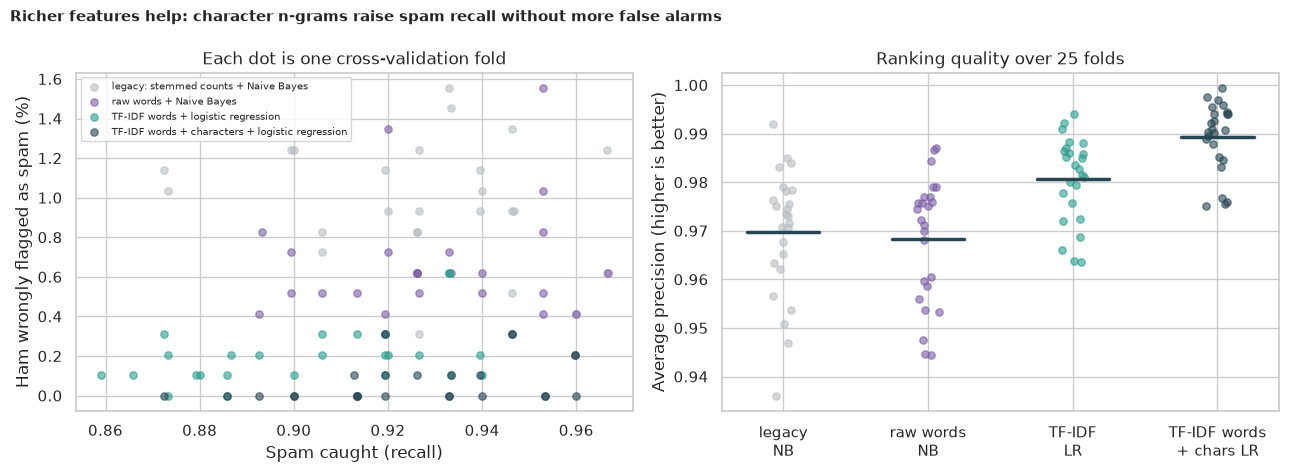

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
order = list(make_models())
colors = [GREY, PURPLE, TEAL, NAVY]
for name, color in zip(order, colors, strict=True):
    sub = all_cv[all_cv["model"] == name]
    axes[0].scatter(
        sub["recall"], sub["false_alarm"] * 100, color=color, alpha=0.6, s=28, label=name
    )
axes[0].set_xlabel("Spam caught (recall)")
axes[0].set_ylabel("Ham wrongly flagged as spam (%)")
axes[0].set_title("Each dot is one cross-validation fold")
axes[0].legend(fontsize=7, loc="upper left")
for i, (name, color) in enumerate(zip(order, colors, strict=True)):
    sub = all_cv[all_cv["model"] == name]["ap"]
    axes[1].scatter(
        np.full(len(sub), i) + rng.uniform(-0.08, 0.08, len(sub)), sub, color=color, alpha=0.6, s=28
    )
    axes[1].plot([i - 0.25, i + 0.25], [sub.mean()] * 2, color=NAVY, lw=2.5)
axes[1].set_xticks(
    range(4), ["legacy\nNB", "raw words\nNB", "TF-IDF\nLR", "TF-IDF words\n+ chars LR"]
)
axes[1].set_ylabel("Average precision (higher is better)")
axes[1].set_title("Ranking quality over 25 folds")
fig.suptitle(
    "Richer features help: character n-grams raise spam recall without more false alarms",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "02_model_comparison.png", dpi=150)
plt.show()

**How to read this (25 grouped folds, mean):**

| model | average precision | accuracy | spam caught | ham wrongly flagged |
|---|---|---|---|---|
| legacy: stemmed counts + Naive Bayes | **0.9697** | 0.9818 | 92.8% | 0.98% |
| raw words + Naive Bayes | **0.9683** | 0.9848 | 92.9% | 0.66% |
| TF-IDF words + logistic regression | **0.9807** | 0.9852 | 90.3% | 0.20% |
| TF-IDF words + characters + logistic regression | **0.9892** | 0.9894 | 92.6% | 0.07% |

- **The richest model is clearly better than the legacy one:** its average precision is **+0.0195** higher (Nadeau-Bengio corrected p < 0.0001, Holm-adjusted). TF-IDF with words alone is **+0.0110** higher (Holm-adjusted p = 0.015). **We reject H₀** for both.
- **Removing stop words and stemming does not matter:** the raw-word Naive Bayes is **-0.0014** from the legacy model (p = 0.65), so that preprocessing earned nothing.
- **The gain is in false alarms, not in catching spam:** all four catch about 90% to 93% of spam at the 0.5 threshold, but the best model wrongly flags only **0.07%** of ham (about 1 real message in 1,400), against **0.98%** (1 in 100) for the legacy model. For a filter, blocking a real message is the costly mistake.

## 10. H5: what if spammers disguise their words?

*What:* real spammers write "FR33" and "pr1z3". We train all four models on **clean** messages, then test them on the **spam messages of a held-out set (187 of them)** after disguising each "e", "o", "a", "i" and "s" with a look-alike digit with probability 0.2, 0.4 or 0.6. We report the share of spam still caught, with 95% Wilson intervals, and compare the best character-based model with the legacy one on the same disguised messages using an exact McNemar test. *Why:* a filter is only useful if it holds up when the other side adapts.

In [10]:
def obfuscate(message: str, gen: np.random.Generator, p: float) -> str:
    """Disguises a message the way spammers do: letters swapped for look-alike symbols.

    Args:
        message: The original text.
        gen: Random number generator.
        p: Chance of swapping each eligible letter.

    Returns:
        The disguised message (e.g. "FREE prize" becomes "FR33 pr1z3").
    """
    table = {"e": "3", "o": "0", "a": "4", "i": "1", "s": "5"}
    return "".join(
        table[c.lower()] if c.lower() in table and gen.random() < p else c for c in message
    )


train_idx, test_idx = next(
    StratifiedGroupKFold(4, shuffle=True, random_state=SEED).split(sms["message"], y, groups)
)
spam_test = test_idx[y[test_idx] == 1]
fitted = {
    name: make_models()[name].fit(model_input(name).iloc[train_idx], y[train_idx])
    for name in make_models()
}
levels = [0.0, 0.2, 0.4, 0.6]
obf_rows = []
for level in levels:
    gen = np.random.default_rng(SEED)
    disguised = pd.Series([obfuscate(m, gen, level) for m in sms["message"].iloc[spam_test]])
    for name, model in fitted.items():
        texts = disguised.map(legacy_clean) if name.startswith("legacy") else disguised
        caught = spam_score(model, texts) > 0.5
        low, high = proportion_confint(int(caught.sum()), len(caught), method="wilson")
        obf_rows.append(
            {"model": name, "level": level, "recall": caught.mean(), "ci_low": low, "ci_high": high}
        )
obf = pd.DataFrame(obf_rows)
print(f"Spam messages in the test part: {len(spam_test)}; models trained on clean text only")
print(
    obf.pivot(index="level", columns="model", values="recall")[list(make_models())]
    .round(3)
    .to_string()
)
at = obf[obf["level"] == 0.6].set_index("model")
print("\nAt a swap chance of 0.6, recall with 95% Wilson interval:")
for name in make_models():
    print(
        f"  {name}: {at.loc[name, 'recall']:.3f} ({at.loc[name, 'ci_low']:.3f} to "
        f"{at.loc[name, 'ci_high']:.3f})"
    )
gen = np.random.default_rng(SEED)
disguised = pd.Series([obfuscate(m, gen, 0.6) for m in sms["message"].iloc[spam_test]])
a_pred = spam_score(fitted[best], disguised) > 0.5
b_pred = spam_score(fitted[name0], disguised.map(legacy_clean)) > 0.5
mc = mcnemar(
    [
        [int((a_pred & b_pred).sum()), int((a_pred & ~b_pred).sum())],
        [int((~a_pred & b_pred).sum()), int((~a_pred & ~b_pred).sum())],
    ],
    exact=True,
)
print(
    f"\nSame disguised spam: character model right and legacy wrong on "
    f"{int((a_pred & ~b_pred).sum())} messages, the reverse on {int((~a_pred & b_pred).sum())}; "
    f"exact McNemar p = {fmt_p(mc.pvalue)}"
)

Spam messages in the test part: 187; models trained on clean text only
model  legacy: stemmed counts + Naive Bayes  raw words + Naive Bayes  TF-IDF words + logistic regression  TF-IDF words + characters + logistic regression
level                                                                                                                                                    
0.0                                   0.941                    0.925                               0.925                                            0.936
0.2                                   0.882                    0.909                               0.893                                            0.930
0.4                                   0.802                    0.893                               0.840                                            0.930
0.6                                   0.658                    0.840                               0.679                                            0.898

At a

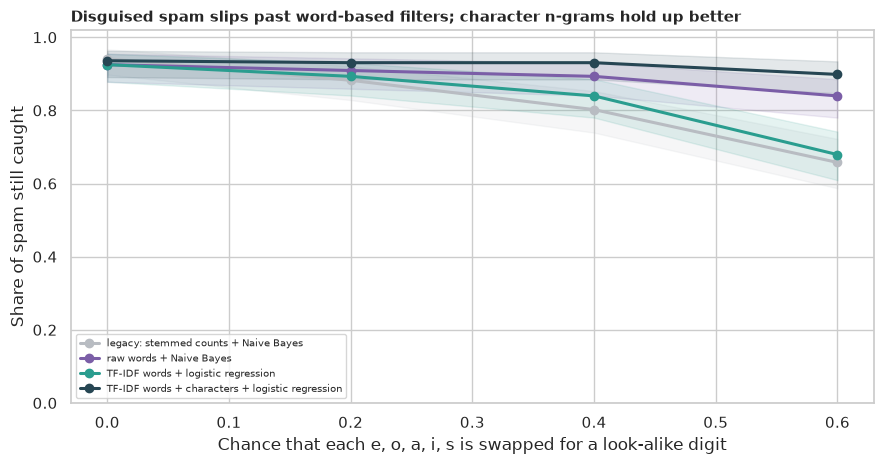

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for name, color in zip(make_models(), colors, strict=True):
    sub = obf[obf["model"] == name]
    ax.plot(sub["level"], sub["recall"], marker="o", lw=2.2, color=color, label=name)
    ax.fill_between(sub["level"], sub["ci_low"], sub["ci_high"], color=color, alpha=0.12)
ax.set_xlabel("Chance that each e, o, a, i, s is swapped for a look-alike digit")
ax.set_ylabel("Share of spam still caught")
ax.set_ylim(0, 1.02)
ax.set_title(
    "Disguised spam slips past word-based filters; character n-grams hold up better",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
ax.legend(fontsize=7, loc="lower left")
fig.tight_layout()
fig.savefig(OUT_DIR / "03_obfuscation.png", dpi=150)
plt.show()

**How to read this:**

- **On clean spam all four catch about the same share:** **94.1%** (legacy), **92.5%** (raw words NB and TF-IDF words) and **93.6%** (words + characters).
- **Disguise hurts word-based filters badly:** at a swap chance of 0.6 the legacy model catches only **65.8%** (95% CI 58.7% to 72.2%) and the TF-IDF word model **67.9%** (60.9% to 74.2%). The raw-word Naive Bayes is surprisingly sturdier at **84.0%** (78.0% to 88.5%): it keeps rare words the others drop.
- **Character n-grams hold up best:** **89.8%** (84.7% to 93.4%) at the same disguise level, down only 3.8 points from clean.
- **Against the legacy model, on the same disguised messages,** the character model is right where the legacy one is wrong on **52** messages and the reverse on **7** (exact McNemar p = 1.4e-9). **We reject H₀.** The extra features are worth far more in the face of an adversary than on clean data.

In [12]:
final = fitted[best]
vec = final.named_steps["vec"]
clf = final.named_steps["clf"]
names = np.array(
    [f"{n.split('__')[0]}: {n.split('__', 1)[1]}" for n in vec.get_feature_names_out()]
)
weights = clf.coef_[0]
top_spam = np.argsort(weights)[::-1][:12]
top_ham = np.argsort(weights)[:12]
print(
    "Strongest spam signals:", ", ".join(f"'{names[i].split(': ')[1].strip()}'" for i in top_spam)
)
print("Strongest ham signals: ", ", ".join(f"'{names[i].split(': ')[1].strip()}'" for i in top_ham))

prob = spam_score(final, sms["message"].iloc[test_idx])
truth = y[test_idx]
wrong = np.flatnonzero((prob > 0.5) != truth)
print(
    f"\nOn the held-out part ({len(test_idx):,} messages) the best model makes {len(wrong)} "
    f"mistakes: {int(((prob > 0.5) & (truth == 0)).sum())} ham flagged as spam and "
    f"{int(((prob <= 0.5) & (truth == 1)).sum())} spam missed"
)
for i in wrong[:5]:
    label = "spam" if truth[i] else "ham"
    print(f"  true {label}, score {prob[i]:.2f}: {sms['message'].iloc[test_idx[i]][:110]!r}")
precision, recall_curve, thresholds = precision_recall_curve(truth, prob)
cost_fp, cost_fn = 10.0, 1.0
cost = [
    cost_fp * ((prob > t) & (truth == 0)).sum() + cost_fn * ((prob <= t) & (truth == 1)).sum()
    for t in thresholds
]
best_t = thresholds[int(np.argmin(cost))]
print(
    f"\nIf wrongly blocking a real message costs 10 times missing a spam, the best threshold "
    f"on this split is {best_t:.2f} (instead of 0.50)."
)

Strongest spam signals: '0', '00', 'txt', '50', '1', '0', 'free', 'call', 'uk', '08', '8', 'www'
Strongest ham signals:  '..', 'me', 'i', 'i', 'my', 'i', '..', 'it', '...', 'got', 'how', 'ok'

On the held-out part (1,394 messages) the best model makes 12 mistakes: 0 ham flagged as spam and 12 spam missed
  true spam, score 0.26: 'Email AlertFrom: Jeri StewartSize: 2KBSubject: Low-cost prescripiton drvgsTo listen to email call 123'
  true spam, score 0.09: 'Filthy stories and GIRLS waiting for your'
  true spam, score 0.20: 'SMS. ac JSco: Energy is high, but u may not know where 2channel it. 2day ur leadership skills r strong. Psychi'
  true spam, score 0.30: 'Monthly password for wap. mobsi.com is 391784. Use your wap phone not PC.'
  true spam, score 0.08: 'Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How '

If wrongly blocking a real message costs 10 times missing a spam, the best threshold on this split is 0.39 (instead of

**How to read this:**

- **The strongest spam signals** are digits and numeric strings ("0", "00", "50", "08"), words like "txt", "free", "call" and "www", and the UK suffix "uk"; the strongest **ham** signals are ellipses ("..", "..."), first-person words ("i", "me", "my") and chat words ("ok", "got", "how"). The model has learned that spam is about *offers and numbers* and ham about *people talking*.
- **On the 1,394 held-out messages the best model makes 12 mistakes: 0 ham flagged as spam and 12 spam messages missed.** The misses are spam that is written like chat ("Babe: U want me dont u baby!...") or disguised ("low-cost prescripiton drvgs"), or short notices with a number and no offer words.
- **The threshold is a business decision:** if wrongly blocking a real message costs ten times missing a spam, the best threshold on this split is **0.39** rather than 0.50, which the model already handles well because it has no false alarms to trade.

## 12. 🎯 Takeaways

1. **Spam is about digits and length:** the number of digits alone has an AUC of 0.965 (Cliff's δ = 0.93), and the median spam is 149 characters against 52.
2. **Two classic leaks did not inflate the score here:** fitting the vocabulary on all messages (-0.05 points, p = 0.25) and duplicate messages across the split (+0.09 points, p = 0.33), even though 11.1% of test messages had an exact copy in training. Check anyway: it cost nothing and ruled them out.
3. **Accuracy is the wrong yardstick** (always "ham" scores 86.6%). Average precision, spam recall and the **false-alarm rate** tell the models apart.
4. **TF-IDF with character n-grams is the best filter:** average precision 0.989 against 0.970 for the legacy model (p < 0.0001), and only 0.07% of ham wrongly flagged against 0.98%. Stemming and stop-word removal added nothing.
5. **Robustness is where the richer features pay off:** against disguised spam the character model keeps 89.8% recall at a disguise level of 0.6, against 65.8% for the legacy model (McNemar p = 1.4e-9).

## 13. ⚠️ Limitations

- **One small, old dataset** (5,574 English text messages collected mostly in Singapore and the UK around 2006); modern spam, other languages and other channels look different.
- **Exact duplicates only.** Near-duplicates (one digit changed) were not grouped, so some leakage may remain in the "grouped" folds.
- **The disguise test is synthetic:** we swapped five letters for look-alike digits at random; real spammers use many other tricks (spacing, emoji, images).
- **The threshold analysis uses one split** and assumed costs (a ham blocked costs 10 times a spam missed); the real ratio depends on the user.
- **One hold-out for the robustness test** (187 spam messages), so its intervals are wide for small differences.
- **No transformer models here:** the companion project `sms-spam-distilbert` compares a fine-tuned DistilBERT with this baseline.